Data Collection

In [7]:
import os
import pandas as pd 
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from fredapi import Fred 
fred = Fred(api_key=os.environ['FRED_API_KEY'])

Pulling Yielf Curves and other economic indicators using Fred Data

In [8]:
import sys
!{sys.executable} -m pip install "accelerate>=1.1.0"

In [9]:
# Economic regime indicators
gdp_growth = fred.get_series('A191RL1Q225SBEA')       # Real GDP growth (quarterly)
cpi = fred.get_series('CPIAUCSL')                      # CPI (monthly)
core_pce = fred.get_series('PCEPILFE')                 # Core PCE - the Fed's preferred measure
unemployment = fred.get_series('UNRATE')                # Unemployment rate
nonfarm_payrolls = fred.get_series('PAYEMS')            # Nonfarm payrolls

# Yield curve
ten_year = fred.get_series('DGS10')                    # 10Y Treasury yield
two_year = fred.get_series('DGS2')                     # 2Y Treasury yield
three_month = fred.get_series('DGS3MO')                # 3M T-bill
thirty_year = fred.get_series('DGS30')                 # 30Y Treasury yield
fed_funds = fred.get_series('DFF')                     # Effective fed funds rate
twoy_ff_spread = two_year - fed_funds

# Spread (you can compute this, but FRED also has it)
ten_two_spread = fred.get_series('T10Y2Y')             # 10Y-2Y spread

# Inflation expectations (critical for regime classification)
breakeven_10y = fred.get_series('T10YIE')              # 10Y breakeven inflation
umich_inflation_exp = fred.get_series('MICH')          # UMich inflation expectations

# Financial conditions
chicago_fed_nfci = fred.get_series('NFCI')             # Financial conditions index

Putting Data together in Data Frame, to classify regime data

In [10]:
core_pce_yoy = core_pce.pct_change(periods=12) * 100



regime_data = pd.DataFrame({
    'GDP Growth': gdp_growth,
    'unemployment': unemployment,
    'cpi': cpi,
    'core_pce': core_pce,
    'fed_funds': fed_funds,
    '10y_yield': ten_year,
    '2y_yield': two_year,
    '10y_2y_spread': ten_two_spread,
    'twoy_ff_spread': twoy_ff_spread,
    'breakeven_10y': breakeven_10y,
    'nfci': chicago_fed_nfci
,'core_pce_yoy': core_pce_yoy})
regime_monthly = regime_data.resample('ME').last()
regime_monthly = regime_monthly.ffill()  # forward-fill quarterly data like GDP

Pulling FOMC Transcripts from the fed website

In [11]:
import requests
from bs4 import BeautifulSoup
import time

base_url = 'https://www.federalreserve.gov'

# Recent meetings (2021-2026)
meeting_dates = [
    '20260128', '20251210', '20251029', '20250917',
    '20250730', '20250618', '20250507', '20250319',
    '20250129', '20241218', '20241107', '20240918',
    '20240731', '20240612', '20240501', '20240320',
    '20240131', '20231213', '20231101', '20230920',
    '20230726', '20230614', '20230503', '20230322',
    '20230201', '20221214', '20221102', '20220921',
    '20220727', '20220615', '20220504', '20220316',
    '20220126', '20211215', '20211103', '20210922',
    '20210728', '20210616', '20210428', '20210317',
    '20210127'
]

# Collect historical dates from 2015-2020
historical_years = list(range(2020, 2014, -1))

for year in historical_years:
    url = f'{base_url}/monetarypolicy/fomchistorical{year}.htm'
    resp = requests.get(url)
    if resp.status_code == 200:
        soup = BeautifulSoup(resp.text, 'html.parser')
        links = soup.find_all('a', href=True)
        for link in links:
            href = link['href']
            if 'pressreleases/monetary' in href and href.endswith('a.htm'):
                date = href.split('monetary')[1].replace('a.htm', '')
                if len(date) == 8 and date.isdigit() and date not in meeting_dates:
                    meeting_dates.append(date)
                    print(f'Found historical date: {date}')
    time.sleep(1)

meeting_dates.sort()
print(f'\nTotal meeting dates: {len(meeting_dates)}')

# Scrape all statements and minutes
statements = {}
minutes = {}

for date in meeting_dates:
    # Fetch statement
    stmt_url = f'{base_url}/newsevents/pressreleases/monetary{date}a.htm'
    resp = requests.get(stmt_url)
    if resp.status_code == 200:
        soup = BeautifulSoup(resp.text, 'html.parser')
        article = (
            soup.find('div', class_='col-xs-12 col-sm-8 col-md-8') or
            soup.find('div', class_='col-xs-12 col-sm-8 col-md-9') or
            soup.find('article')
        )
        if article:
            statements[date] = article.get_text(strip=True)
            print(f'Statement: {date}')

    # Fetch minutes
    min_url = f'{base_url}/monetarypolicy/fomcminutes{date}.htm'
    resp = requests.get(min_url)
    if resp.status_code == 200:
        soup = BeautifulSoup(resp.text, 'html.parser')
        article = (
            soup.find('div', class_='col-xs-12 col-sm-8 col-md-9') or
            soup.find('div', class_='col-xs-12 col-sm-8 col-md-8') or
            soup.find('article')
        )
        if article:
            minutes[date] = article.get_text(strip=True)
            print(f'Minutes: {date}')

    time.sleep(1)

print(f'\nTotal statements: {len(statements)}')
print(f'Total minutes: {len(minutes)}')
print(f'Date range: {min(statements.keys())} to {max(statements.keys())}')

Found historical date: 20200129
Found historical date: 20200303
Found historical date: 20200315
Found historical date: 20200323
Found historical date: 20200331
Found historical date: 20200429
Found historical date: 20200610
Found historical date: 20200729
Found historical date: 20200827
Found historical date: 20200916
Found historical date: 20201105
Found historical date: 20201216
Found historical date: 20190130
Found historical date: 20190320
Found historical date: 20190501
Found historical date: 20190619
Found historical date: 20190731
Found historical date: 20190918
Found historical date: 20191011
Found historical date: 20191030
Found historical date: 20191211
Found historical date: 20180131
Found historical date: 20180321
Found historical date: 20180502
Found historical date: 20180613
Found historical date: 20180801
Found historical date: 20180926
Found historical date: 20181108
Found historical date: 20181219
Found historical date: 20170201
Found historical date: 20170315
Found hi

Macro Economic Regime Classifier

In [12]:
def classify_economic_regime(regime_data):
    # Get latest values
    gdp = regime_data['GDP Growth']
    unemployment = regime_data['unemployment']
    inflation = regime_data['core_pce_yoy']  # YoY
    fed_funds = regime_data['fed_funds']
    spread_10y2y = regime_data['10y_2y_spread']
    
    # --- Growth Regime ---
    if gdp < -1:
        growth = 'deep_contraction'
    elif gdp < 0:
        growth = 'contraction'
    elif gdp < 1.5:
        growth = 'below_trend'
    elif gdp < 3.0:
        growth = 'trend'
    elif gdp < 5.0:
        growth = 'above_trend'
    else:
        growth = 'overheating'
    
    # --- Inflation Regime ---
    if inflation < 1.0:
        infl = 'deflationary'
    elif inflation < 1.5:
        infl = 'below_target'
    elif inflation < 2.5:
        infl = 'at_target'
    elif inflation < 4.0:
        infl = 'above_target'
    elif inflation < 6.0:
        infl = 'high'
    else:
        infl = 'very_high'
    
    # --- Labor Market Regime ---
    if unemployment < 3.5:
        labor = 'very_tight'
    elif unemployment < 4.5:
        labor = 'tight'
    elif unemployment < 5.5:
        labor = 'neutral'
    elif unemployment < 7.0:
        labor = 'loose'
    else:
        labor = 'very_loose'
    
    # --- Monetary Policy Stance ---
    # Compare fed funds to a neutral rate estimate (~2.5%)
    real_rate = fed_funds - inflation
    if real_rate < -1.0:
        policy = 'very_accommodative'
    elif real_rate < 0.5:
        policy = 'accommodative'
    elif real_rate < 1.5:
        policy = 'neutral'
    elif real_rate < 2.5:
        policy = 'restrictive'
    else:
        policy = 'very_restrictive'
    
    # --- Yield Curve Regime ---
    if spread_10y2y < -0.5:
        curve = 'deeply_inverted'
    elif spread_10y2y < 0:
        curve = 'inverted'
    elif spread_10y2y < 0.5:
        curve = 'flat'
    elif spread_10y2y < 1.5:
        curve = 'normal'
    else:
        curve = 'steep'
    
    # --- Combined Macro Regime ---
    if gdp < 0 and inflation > 3.0:
        combined = 'stagflation'
    elif gdp < 0 and inflation < 2.0:
        combined = 'deflationary_recession'
    elif gdp > 3.0 and inflation > 3.0:
        combined = 'overheating'
    elif gdp > 1.5 and inflation < 2.5:
        combined = 'goldilocks'
    elif gdp < 1.5 and inflation < 2.0:
        combined = 'secular_stagnation'
    elif gdp > 1.5 and inflation > 2.5:
        combined = 'reflation'
    else:
        combined = 'transition'
    
    return {
        'growth': growth,
        'inflation': infl,
        'labor_market': labor,
        'monetary_policy': policy,
        'yield_curve': curve,
        'combined_regime': combined
    }

In [13]:
regime_classifications = {}

for date, row in regime_monthly.dropna().iterrows():
    try:
        regime_classifications[date] = classify_economic_regime(row)
    except:
        regime_classifications[date] = None

regime_class_df = pd.DataFrame(regime_classifications).T
regime_monthly_plusclassification = regime_monthly.join(regime_class_df)

In [14]:
import pandas as pd

# Your statements dict is keyed by date strings like '20260128'
# Convert to datetime so we can match with regime_monthly

fomc_data = []

for date_str, text in statements.items():
    # Parse the date
    date = pd.to_datetime(date_str)
    
    # Find the most recent monthly regime data as of that FOMC date
    # (regime data is month-end, so we look for the last month before the meeting)
    regime_date = regime_monthly_plusclassification.index[
        regime_monthly_plusclassification.index <= date
    ][-1]
    
    regime_row = regime_monthly_plusclassification.loc[regime_date]
    
    fomc_data.append({
        'date': date,
        'statement': text,
        'minutes': minutes.get(date_str, None),
        'combined_regime': regime_row['combined_regime'],
        'GDP Growth': regime_row['GDP Growth'],
        'core_pce_yoy': regime_row['core_pce_yoy'],
        'unemployment': regime_row['unemployment'],
        'fed_funds': regime_row['fed_funds'],
        '10y_yield': regime_row['10y_yield'],
        '2y_yield' : regime_row['2y_yield'],
        'twoy_ff_spread': regime_row['twoy_ff_spread']
    })

fomc_df = pd.DataFrame(fomc_data).sort_values('date')
fomc_df = fomc_df.set_index('date')


Regression Model

In [15]:
one_year_daily = fred.get_series('DGS1')

fomc_df['1y_60d_change'] = None
for date in fomc_df.index:
    try:
        loc = one_year_daily.index.get_indexer([date], method='ffill')[0]
        if loc + 44 < len(one_year_daily):
            fomc_df.loc[date, '1y_60d_change'] = one_year_daily.iloc[loc + 44] - one_year_daily.iloc[loc]
    except:
        pass
fomc_df['1y_60d_change'] = fomc_df['1y_60d_change'].astype(float)
print(f'1y_60d_change built: {fomc_df["1y_60d_change"].notna().sum()} observations')

1y_60d_change built: 91 observations


In [16]:
import torch
import numpy as np
import random

random.seed(24)
np.random.seed(24)
torch.manual_seed(24)

In [17]:
sentence_training = [
    # === RATE DECISIONS === 
    ("The Committee decided to raise the target range for the federal funds rate by 75 basis points", 0.95),
    ("The Committee decided to raise the target range for the federal funds rate by 50 basis points", 0.85),
    ("The Committee decided to raise the target range for the federal funds rate by 25 basis points", 0.75),
    ("The Committee decided to maintain the target range for the federal funds rate", 0.5),
    ("The Committee decided to lower the target range for the federal funds rate by 25 basis points", 0.25),
    ("The Committee decided to lower the target range for the federal funds rate by 50 basis points", 0.15),
    ("The Committee expects it will soon be appropriate to raise the target range for the federal funds rate", 0.85),
    ("It would be premature to begin lowering rates at this time", 0.8),
    
    # === FORWARD GUIDANCE - HAWKISH ===
    ("The Committee anticipates that ongoing increases in the target range will be appropriate", 0.9),
    ("The Committee is strongly committed to returning inflation to its 2 percent objective", 0.8),
    ("The Committee is prepared to raise rates further if appropriate", 0.85),
    ("Additional policy firming may be appropriate", 0.8),
    ("The Committee will continue reducing its holdings of Treasury securities and agency debt", 0.75),
    ("The Committee decided to continue to reduce the monthly pace of its net asset purchases", 0.7),
    ("Ongoing increases in the target range will be appropriate to bring inflation down", 0.85),
    ("The Committee will take into account the cumulative tightening of monetary policy", 0.65),
    
    # === FORWARD GUIDANCE - DOVISH ===
    ("The Committee is prepared to adjust the stance of monetary policy as appropriate if risks emerge", 0.35),
    ("The Committee would be prepared to adjust the stance of monetary policy as appropriate", 0.4),
    ("The Committee judges that the risks have become more balanced", 0.3),
    ("The risks to achieving its employment and inflation goals are roughly in balance", 0.3),
    ("The Committee is attentive to the risks to both sides of its dual mandate", 0.35),
    ("In considering additional adjustments the Committee will carefully assess incoming data", 0.4),
    ("The Committee does not expect it will be appropriate to reduce the target range until it has gained greater confidence", 0.55),
    
    # === INFLATION - HAWKISH ===
    ("Inflation remains elevated", 0.8),
    ("Inflation remains well above the Committee's 2 percent objective", 0.85),
    ("Inflation remains somewhat elevated", 0.65),
    ("Inflation continues to run well above the longer-run goal", 0.85),
    ("Core inflation remains elevated and persistent", 0.85),
    ("Price pressures remain broad based across sectors", 0.8),
    ("Inflation has shown little progress toward the 2 percent objective", 0.85),
    ("Supply and demand imbalances have continued to contribute to elevated levels of inflation", 0.75),
    ("Wage growth remains elevated relative to what would be consistent with price stability", 0.8),
    ("Housing costs continue to put upward pressure on overall inflation", 0.75),
    ("Inflation expectations risk becoming unanchored", 0.9),
    
    # === INFLATION - DOVISH ===
    ("Inflation has eased over the past year but remains above the Committee's target", 0.55),
    ("Inflation has made progress toward the Committee's 2 percent objective", 0.3),
    ("Inflation has made further progress toward the Committee's 2 percent objective", 0.25),
    ("Inflation has declined significantly from its peak", 0.2),
    ("The disinflationary process has continued", 0.2),
    ("Inflation has come down considerably over the past year", 0.25),
    ("Longer-term inflation expectations remain well anchored", 0.35),
    ("Inflation has moved closer to the Committee's 2 percent objective", 0.3),
    
    # === LABOR MARKET - HAWKISH ===
    ("The labor market remains extremely tight", 0.8),
    ("Job gains have been robust in recent months", 0.75),
    ("Job gains have been strong", 0.7),
    ("The unemployment rate has remained low", 0.65),
    ("Demand continues to outstrip supply in the labor market", 0.8),
    ("Consumer spending has been particularly strong", 0.75),
    ("Consumer spending has been surprisingly resilient", 0.7),
    ("Job gains have been solid in recent months and the unemployment rate has declined substantially", 0.7),
    
    # === LABOR MARKET - DOVISH ===
    ("Job gains have moderated", 0.35),
    ("Job gains have slowed", 0.3),
    ("The unemployment rate has moved up but remains low", 0.35),
    ("The labor market is showing signs of softening", 0.25),
    ("Job gains have remained low and the unemployment rate has shown some signs of stabilization", 0.35),
    ("Employment gains have slowed significantly", 0.2),
    
    # === ECONOMIC ACTIVITY - HAWKISH ===
    ("Economic activity has been expanding at a strong pace", 0.75),
    ("Economic activity has been expanding at a solid pace", 0.65),
    ("Available indicators suggest that economic activity has been expanding at a solid pace", 0.65),
    ("The economy has been stronger than expected", 0.75),
    ("Recent indicators suggest that economic activity has continued to expand at a solid pace", 0.65),
    ("Indicators of economic activity and employment have continued to strengthen", 0.7),
    
    # === ECONOMIC ACTIVITY - DOVISH ===
    ("Economic activity has slowed from its strong pace", 0.35),
    ("Economic activity has slowed considerably", 0.2),
    ("Growth has moderated from its earlier pace", 0.3),
    ("Recent indicators point to modest growth in spending and production", 0.35),
    ("The path of the economy continues to depend on the course of the virus", 0.3),
    ("Economic activity expanded at a moderate rate", 0.4),
    
    # === FINANCIAL CONDITIONS ===
    ("Overall financial conditions remain accommodative", 0.3),
    ("Financial conditions have tightened significantly", 0.25),
    ("Credit conditions have become more restrictive for households and businesses", 0.25),
    ("Tighter credit conditions for households and businesses are likely to weigh on economic activity", 0.2),
    ("The Federal Reserve's ongoing purchases will continue to foster smooth market functioning and accommodative financial conditions", 0.3),
    
    # === BALANCE SHEET ===
    ("The Committee will continue reducing its holdings of Treasury securities", 0.7),
    ("The Committee decided to begin reducing its holdings at a pace of 95 billion per month", 0.75),
    ("The Committee decided to slow the pace of decline of its securities holdings", 0.35),
    ("Beginning in February the Committee will increase its holdings of Treasury securities", 0.2),
    ("The Committee will increase its holdings of agency mortgage-backed securities", 0.2),
    
    # === RISKS ===
    ("Risks to the economic outlook remain including from new variants of the virus", 0.25),
    ("Uncertainty about the economic outlook has increased", 0.3),
    ("Uncertainty about the economic outlook remains elevated", 0.35),
    ("The Committee sees the risks to achieving its goals as roughly in balance", 0.4),
    ("Risks to the economic outlook are weighted to the downside", 0.15),
    ("Upside risks to inflation remain", 0.8),
    
    # === BOILERPLATE - NEUTRAL ===
    ("The Committee seeks to achieve maximum employment and inflation at the rate of 2 percent over the longer run", 0.5),
    ("The Committee will continue to monitor the implications of incoming information for the economic outlook", 0.5),
    ("The Committee's assessments will take into account a wide range of information", 0.5),
    ("In assessing the appropriate stance of monetary policy the Committee will continue to monitor", 0.5),
]

In [18]:

import torch
import numpy as np
import random

random.seed(24)
np.random.seed(24)
torch.manual_seed(24)

from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
import torch
from torch.utils.data import Dataset

model_name = 'distilbert-base-uncased'
tokenizer = AutoTokenizer.from_pretrained(model_name)
sent_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=1)

device = torch.device('cpu')
sent_model = sent_model.to(device)

texts = [s[0] for s in sentence_training]
scores = [s[1] for s in sentence_training]

print(f'Training sentences: {len(texts)}')

class SentDataset(Dataset):
    def __init__(self, texts, scores):
        self.encodings = tokenizer(texts, truncation=True, padding=True, max_length=128, return_tensors='pt')
        self.labels = torch.tensor(scores, dtype=torch.float32)
    def __getitem__(self, idx):
        item = {k: v[idx] for k, v in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item
    def __len__(self):
        return len(self.labels)

dataset = SentDataset(texts, scores)

training_args = TrainingArguments(
    output_dir='./fed_sentence_model',
    num_train_epochs=30,
    per_device_train_batch_size=8,
    learning_rate=2e-5,
    logging_steps=50,
    save_strategy='no',
    use_cpu=True
)

trainer = Trainer(model=sent_model, args=training_args, train_dataset=dataset)
trainer.train()
print('Sentence-level model training complete')

C:\Users\dcost\sde1_code\HooHacks-2026-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9108.35it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those

Training sentences: 88


Step,Training Loss
50,0.057536
100,0.014762
150,0.006180
200,0.004557
250,0.004344
300,0.003895


Sentence-level model training complete


In [19]:
def score_sentence_model(text):
    sentences = text.split('.')
    scores = []
    
    skip_patterns = [
        'Voting for', 'Voting against', 'Vice Chair', 'Chair;',
        'media inquiries', 'email', 'Implementation Note',
        'For release', 'press@', 'call 202',
        'Brainard', 'Bullard', 'Bowman', 'Harker', 'Mester',
        'Kashkari', 'George', 'Kaplan', 'Clarida', 'Waller',
        'Jefferson', 'Cook', 'Hammack', 'Logan', 'Paulson',
        'Miran', 'Barr', 'Williams', 'Powell'
    ]
    
    for sent in sentences:
        sent = sent.strip()
        if len(sent) < 20:
            continue
        if any(skip in sent for skip in skip_patterns):
            continue
        
        inputs = tokenizer(sent, return_tensors='pt', truncation=True, max_length=128)
        inputs = {k: v.to(device) for k, v in inputs.items()}
        
        with torch.no_grad():
            outputs = sent_model(**inputs)
        
        scores.append(outputs.logits.cpu().numpy()[0][0])
    
    return np.mean(scores) if scores else 0.5

print('Scoring with sentence-level model...')
for date, row in fomc_df.iterrows():
    if pd.notna(row.get('statement')):
        fomc_df.loc[date, 'sent_level'] = score_sentence_model(row['statement'])

fomc_df['sent_level'] = fomc_df['sent_level'].astype(float)
fomc_df['sent_level_demeaned'] = fomc_df['sent_level'] - fomc_df['sent_level'].mean()
print('Scoring complete')

# Test
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut
import numpy as np

target = '1y_60d_change'
loo = LeaveOneOut()

feature_sets = {
    'Sentence-level + spread': ['sent_level_demeaned', 'twoy_ff_spread'],
    'Spread only': ['twoy_ff_spread'],
}

print(f'\n{"Feature Set":<40} {"In R²":>8} {"OOS R²":>8} {"Dir %":>8} {"Obs":>6}')
print('-' * 75)

for name, features in feature_sets.items():
    try:
        md = fomc_df[[target] + features].dropna()
        X = md[features]
        y = md[target]
        
        reg_full = LinearRegression()
        reg_full.fit(X, y)
        in_r2 = reg_full.score(X, y)
        
        preds = []
        acts = []
        for train_idx, test_idx in loo.split(X):
            reg = LinearRegression()
            reg.fit(X.iloc[train_idx], y.iloc[train_idx])
            preds.append(reg.predict(X.iloc[test_idx])[0])
            acts.append(y.iloc[test_idx].values[0])
        
        preds = np.array(preds)
        acts = np.array(acts)
        ss_res = np.sum((acts - preds) ** 2)
        ss_tot = np.sum((acts - acts.mean()) ** 2)
        direction = np.mean(np.sign(preds) == np.sign(acts))
        
        print(f'{name:<40} {in_r2:>8.3f} {1-ss_res/ss_tot:>8.3f} {direction:>7.1%} {len(y):>6}')
    except Exception as e:
        print(f'{name:<40} ERROR: {e}')

Scoring with sentence-level model...
Scoring complete

Feature Set                                 In R²   OOS R²    Dir %    Obs
---------------------------------------------------------------------------
Sentence-level + spread                     0.256    0.195   69.2%     91
Spread only                                 0.254    0.208   63.7%     91


In [20]:
one_year_daily = fred.get_series('DGS1')

fomc_df['1y_yield'] = None
for date in fomc_df.index:
    try:
        loc = one_year_daily.index.get_indexer([date], method='ffill')[0]
        fomc_df.loc[date, '1y_yield'] = one_year_daily.iloc[loc]
    except:
        pass
fomc_df['1y_yield'] = fomc_df['1y_yield'].astype(float)

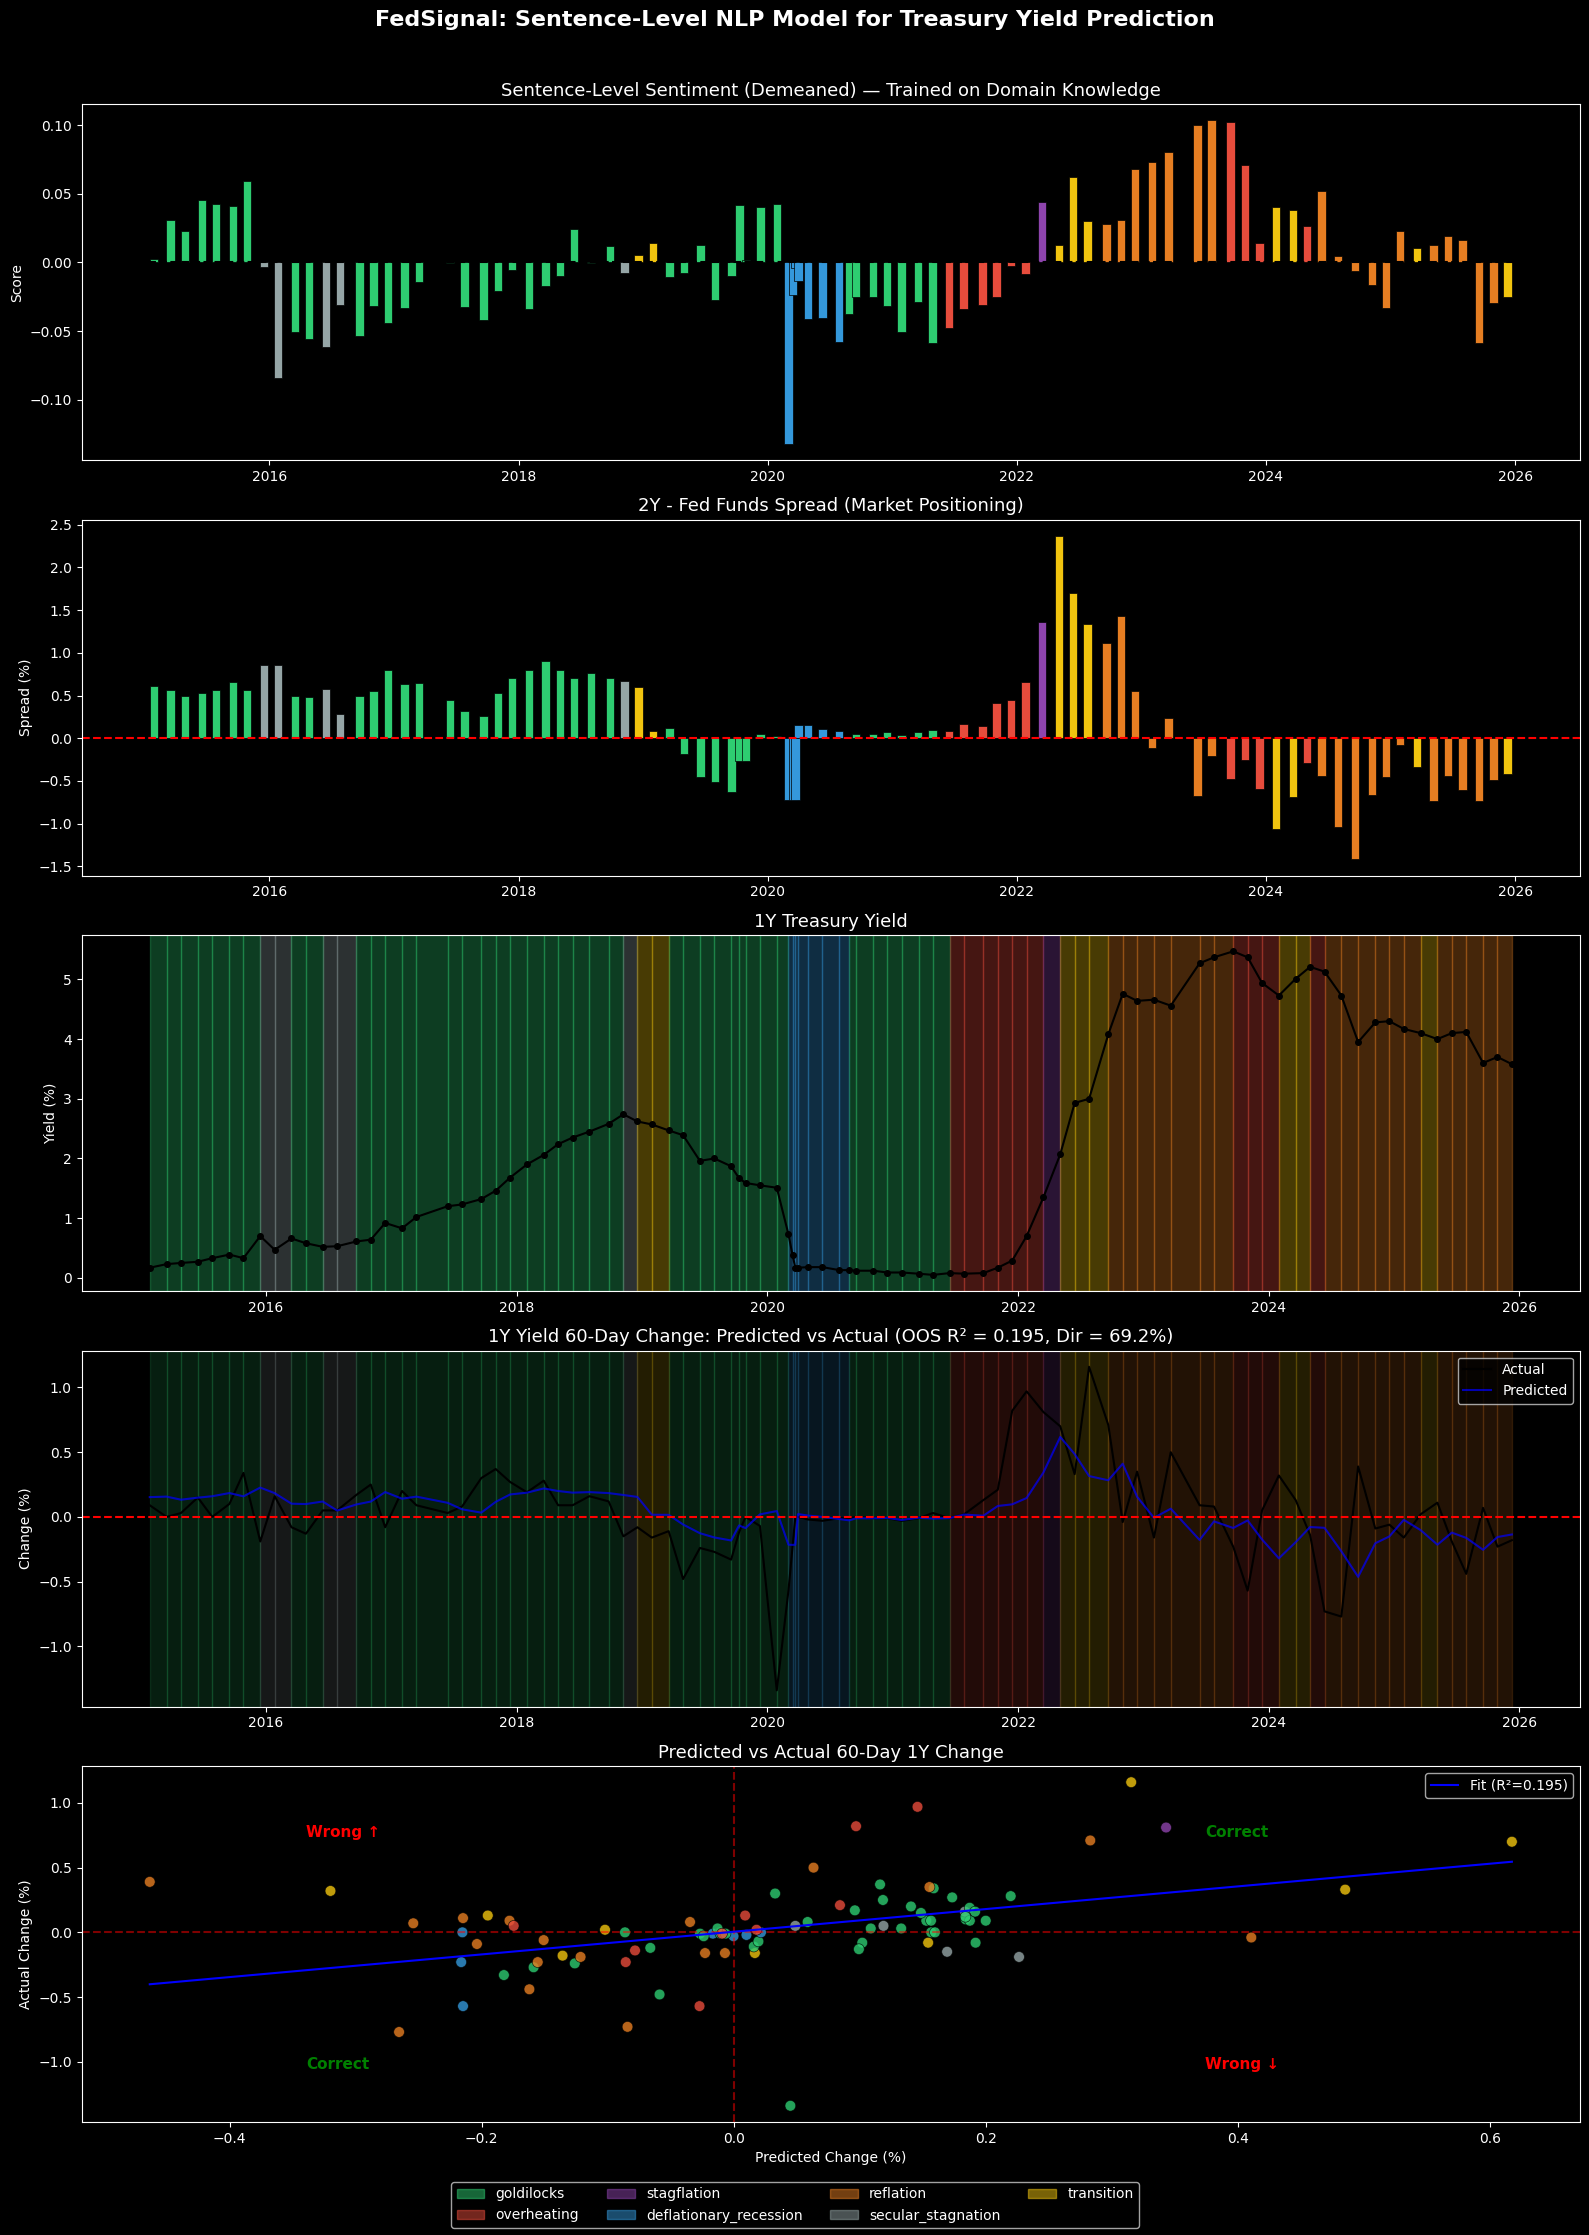


Model: sent_level_demeaned + twoy_ff_spread → 1y_60d_change
Coefficients:
  sent_level_demeaned: 0.4274
  twoy_ff_spread:     0.2687
  Intercept:          -0.0131


In [21]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut

# Build model predictions
features_best = ['sent_level_demeaned', 'twoy_ff_spread']
target = '1y_60d_change'

model_data = fomc_df[[target, 'sent_level_demeaned', 'twoy_ff_spread', '1y_yield', 'combined_regime']].dropna()
X = model_data[features_best]
y = model_data[target]

# Leave-one-out predictions
loo = LeaveOneOut()
preds = []
acts = []

for train_idx, test_idx in loo.split(X):
    reg = LinearRegression()
    reg.fit(X.iloc[train_idx], y.iloc[train_idx])
    preds.append(reg.predict(X.iloc[test_idx])[0])
    acts.append(y.iloc[test_idx].values[0])

preds = np.array(preds)
acts = np.array(acts)

# Full model for coefficients
reg_full = LinearRegression()
reg_full.fit(X, y)

regime_colors = {
    'goldilocks': '#2ecc71',
    'overheating': '#e74c3c',
    'stagflation': '#8e44ad',
    'deflationary_recession': '#3498db',
    'reflation': '#e67e22',
    'secular_stagnation': '#95a5a6',
    'transition': '#f1c40f'
}

colors = [regime_colors.get(r, '#f1c40f') for r in model_data['combined_regime']]

fig, axes = plt.subplots(5, 1, figsize=(16, 22))

# --- 1: Sentence-Level Sentiment ---
axes[0].bar(model_data.index, model_data['sent_level_demeaned'], width=25, color=colors, edgecolor='black', linewidth=0.5)
axes[0].axhline(y=0, color='black', linestyle='--')
axes[0].set_title('Sentence-Level Sentiment (Demeaned) — Trained on Domain Knowledge', fontsize=13)
axes[0].set_ylabel('Score')

# --- 2: 2Y-FF Spread ---
axes[1].bar(model_data.index, model_data['twoy_ff_spread'], width=25, color=colors, edgecolor='black', linewidth=0.5)
axes[1].axhline(y=0, color='red', linestyle='--')
axes[1].set_title('2Y - Fed Funds Spread (Market Positioning)', fontsize=13)
axes[1].set_ylabel('Spread (%)')

# --- 3: 1Y Yield with Regime Colors ---
axes[2].plot(model_data.index, model_data['1y_yield'], color='black', linewidth=1.5, marker='o', markersize=4)
for i in range(len(model_data) - 1):
    regime = model_data['combined_regime'].iloc[i]
    color = regime_colors.get(regime, '#f1c40f')
    axes[2].axvspan(model_data.index[i], model_data.index[i + 1], alpha=0.3, color=color)
axes[2].set_title('1Y Treasury Yield', fontsize=13)
axes[2].set_ylabel('Yield (%)')

# --- 4: Predicted vs Actual ---
axes[3].plot(model_data.index, acts, label='Actual', color='black', linewidth=1.5)
axes[3].plot(model_data.index, preds, label='Predicted', color='blue', linewidth=1.5, alpha=0.7)
axes[3].axhline(y=0, color='red', linestyle='--')
for i in range(len(model_data) - 1):
    regime = model_data['combined_regime'].iloc[i]
    color = regime_colors.get(regime, '#f1c40f')
    axes[3].axvspan(model_data.index[i], model_data.index[i + 1], alpha=0.15, color=color)
axes[3].set_title(f'1Y Yield 60-Day Change: Predicted vs Actual (OOS R² = 0.195, Dir = 69.2%)', fontsize=13)
axes[3].set_ylabel('Change (%)')
axes[3].legend()

# --- 5: Scatter with Regime Colors ---
axes[4].scatter(preds, acts, c=colors, edgecolor='black', linewidth=0.5, s=60, alpha=0.8)
axes[4].axhline(y=0, color='red', linestyle='--', alpha=0.5)
axes[4].axvline(x=0, color='red', linestyle='--', alpha=0.5)
z = np.polyfit(preds, acts, 1)
p = np.poly1d(z)
x_line = np.linspace(min(preds), max(preds), 100)
axes[4].plot(x_line, p(x_line), color='blue', linestyle='-', linewidth=1.5, label=f'Fit (R²=0.195)')
axes[4].set_title('Predicted vs Actual 60-Day 1Y Change', fontsize=13)
axes[4].set_xlabel('Predicted Change (%)')
axes[4].set_ylabel('Actual Change (%)')
axes[4].legend()

# Add quadrant labels to scatter
axes[4].text(0.15, 0.8, 'Wrong ↑', transform=axes[4].transAxes, fontsize=11, color='red', fontweight='bold')
axes[4].text(0.75, 0.15, 'Wrong ↓', transform=axes[4].transAxes, fontsize=11, color='red', fontweight='bold')
axes[4].text(0.15, 0.15, 'Correct', transform=axes[4].transAxes, fontsize=11, color='green', fontweight='bold')
axes[4].text(0.75, 0.8, 'Correct', transform=axes[4].transAxes, fontsize=11, color='green', fontweight='bold')

# Regime legend
patches = [mpatches.Patch(color=color, alpha=0.5, label=regime) for regime, color in regime_colors.items()]
fig.legend(handles=patches, loc='lower center', ncol=4, fontsize=10)

# Model info
fig.suptitle('FedSignal: Sentence-Level NLP Model for Treasury Yield Prediction', fontsize=16, fontweight='bold', y=1.01)

plt.tight_layout()
plt.subplots_adjust(bottom=0.05)
plt.show()

# Print model details
print(f'\nModel: sent_level_demeaned + twoy_ff_spread → 1y_60d_change')
print(f'Coefficients:')
print(f'  sent_level_demeaned: {reg_full.coef_[0]:.4f}')
print(f'  twoy_ff_spread:     {reg_full.coef_[1]:.4f}')
print(f'  Intercept:          {reg_full.intercept_:.4f}')